In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import json
import os
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [3]:
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)


In [4]:
print(combined_df.columns)


Index(['subreddit', 'author', 'date', 'post', 'automated_readability_index',
       'coleman_liau_index', 'flesch_kincaid_grade_level',
       'flesch_reading_ease', 'gulpease_index', 'gunning_fog_index',
       ...
       'tfidf_without', 'tfidf_wonder', 'tfidf_work', 'tfidf_worri',
       'tfidf_wors', 'tfidf_would', 'tfidf_wrong', 'tfidf_x200b', 'tfidf_year',
       'subreddit_name'],
      dtype='object', length=351)


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import joblib
import pandas as pd

#  Prepare Reddit labels
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

#  Fit a TF-IDF vectorizer on Reddit text
reddit_texts = combined_df['post'].astype(str)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X = vectorizer.fit_transform(reddit_texts)
y = combined_df['label']

#  Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#  Train SVM
svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X_train, y_train)

#  Evaluate on Reddit test set
y_pred = svm.predict(X_test)
print(" Reddit Accuracy:", accuracy_score(y_test, y_pred))
print("\n Reddit Classification Report:\n", classification_report(y_test, y_pred))

#  Save model and vectorizer for later Twitter predictions
joblib.dump(svm, "svm_reddit_tfidf.pkl")
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")


 Reddit Accuracy: 0.9341476154124312

 Reddit Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95     16982
           1       0.88      0.92      0.90      7907

    accuracy                           0.93     24889
   macro avg       0.92      0.93      0.93     24889
weighted avg       0.94      0.93      0.93     24889



['tfidf_reddit_vectorizer.pkl']

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import joblib
import json

#  Prepare labels
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

#  TF-IDF features
reddit_texts = combined_df['post'].astype(str)
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X = vectorizer.fit_transform(reddit_texts)
y = combined_df['label']

#  Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

#  Define parameter grid for tuning
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'class_weight': [None, 'balanced'],
    'max_iter': [2000, 5000]
}

#  Grid Search CV
grid_search = GridSearchCV(
    estimator=LinearSVC(),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

#  Best model and evaluation
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print("Best Parameters:", grid_search.best_params_)
print(f"Reddit Accuracy: {acc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

#  Save model, vectorizer, and tuning log
joblib.dump(best_model, "svm_reddit_tfidf_best.pkl")
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")

#  Save tuning log as JSON (for report / GitHub)
log = {
    "best_params": grid_search.best_params_,
    "best_score": grid_search.best_score_,
    "test_accuracy": acc,
}
with open("svm_tuning_log.json", "w") as f:
    json.dump(log, f, indent=4)


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'C': 1, 'class_weight': None, 'max_iter': 2000}
Reddit Accuracy: 0.9391

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.96      0.96     16982
           1       0.92      0.89      0.90      7907

    accuracy                           0.94     24889
   macro avg       0.93      0.93      0.93     24889
weighted avg       0.94      0.94      0.94     24889



In [37]:
import joblib

# After training your model and vectorizer
joblib.dump(svm, "svm_reddit_tfidf.pkl")          # save trained SVM
joblib.dump(vectorizer, "tfidf_reddit_vectorizer.pkl")  # save TF-IDF vectorizer


['tfidf_reddit_vectorizer.pkl']

In [38]:
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
print(twitter_df.columns)


Index(['Unnamed: 0', 'post_id', 'post_created', 'post_text', 'user_id',
       'followers', 'friends', 'favourites', 'statuses', 'retweets', 'label'],
      dtype='object')


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'C': 1, 'class_weight': None, 'max_iter': 1000}

Twitter Accuracy: 0.7972

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.83      0.80     10000
           1       0.82      0.77      0.79     10000

    accuracy                           0.80     20000
   macro avg       0.80      0.80      0.80     20000
weighted avg       0.80      0.80      0.80     20000



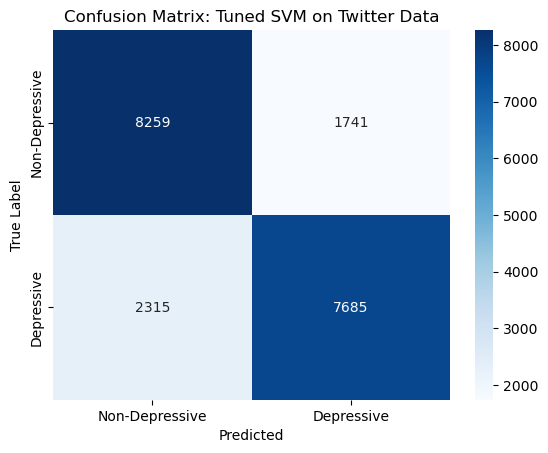

In [8]:
import pandas as pd
import joblib
import re
import string
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------
# Load trained Reddit TF-IDF vectorizer
# ------------------------------
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")

# ------------------------------
# Load and preprocess Twitter dataset
# ------------------------------
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")

def preprocess_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)      # remove URLs
    text = re.sub(r"@\w+", "", text)                # remove mentions
    text = re.sub(r"#(\w+)", r"\1", text)           # remove # but keep word
    text = re.sub(r"[^\w\s,]", "", text)            # remove punctuation/emojis
    text = re.sub(r'\d+', '', text)                 # remove numbers
    text = re.sub(r'\s+', ' ', text).strip()        # normalize spaces
    return text

twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_tweet)

# Transform Twitter text
X_twitter = vectorizer.transform(twitter_df["clean_text"])
y_twitter = twitter_df["label"]

# ------------------------------
# Hyperparameter tuning using GridSearchCV
# ------------------------------
param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"],
    "max_iter": [1000, 2000]
}

svm_model = LinearSVC()
grid_search = GridSearchCV(svm_model, param_grid, cv=5, verbose=1, n_jobs=-1)
grid_search.fit(X_twitter, y_twitter)

print("Best Parameters:", grid_search.best_params_)
best_svm = grid_search.best_estimator_

# ------------------------------
# Save tuned model
# ------------------------------
joblib.dump(best_svm, "svm_twitter_tuned.pkl")

# ------------------------------
# Evaluate tuned model
# ------------------------------
predicted_depression = best_svm.predict(X_twitter)

print("\nTwitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\nClassification Report:\n", classification_report(y_twitter, predicted_depression, zero_division=0))

# ------------------------------
# Visualize confusion matrix
# ------------------------------
cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Tuned SVM on Twitter Data")
plt.show()


Twitter Accuracy: 0.5

Classification Report:
               precision    recall  f1-score   support

           0       0.50      1.00      0.67     10000
           1       0.00      0.00      0.00     10000

    accuracy                           0.50     20000
   macro avg       0.25      0.50      0.33     20000
weighted avg       0.25      0.50      0.33     20000



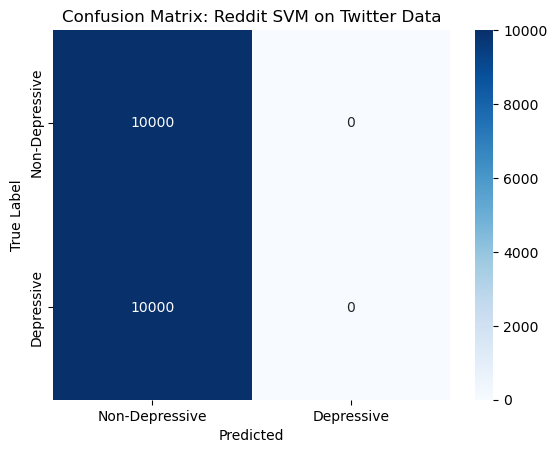

In [7]:
import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

#  Load trained Reddit SVM and TF-IDF vectorizer 
svm = joblib.load("svm_reddit_tfidf.pkl")
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")  # if you saved it earlier

#  Load Twitter dataset 
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")

#  Prepare features and labels 
X_twitter = vectorizer.transform(twitter_df['post_text'].astype(str))
y_twitter = twitter_df['label']

#  Predict using Reddit-trained SVM 
twitter_preds = svm.predict(X_twitter)

#  Map Reddit subreddit predictions to Depressive / Non-Depressive 
depressive_subs = ["suicidewatch", "anxiety", "depression", "mentalhealth", "addiction", "alcoholism"]
predicted_depression = [1 if p in depressive_subs else 0 for p in twitter_preds]

#  Evaluate performance 
print("Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\nClassification Report:\n", classification_report(y_twitter, predicted_depression, zero_division=0))

#  Confusion matrix 
cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Non-Depressive","Depressive"],
            yticklabels=["Non-Depressive","Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit SVM on Twitter Data")
plt.show()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


 Twitter Accuracy: 0.57245

Twitter Classification Report:
               precision    recall  f1-score   support

           0       0.55      0.84      0.66     10000
           1       0.66      0.30      0.42     10000

    accuracy                           0.57     20000
   macro avg       0.60      0.57      0.54     20000
weighted avg       0.60      0.57      0.54     20000



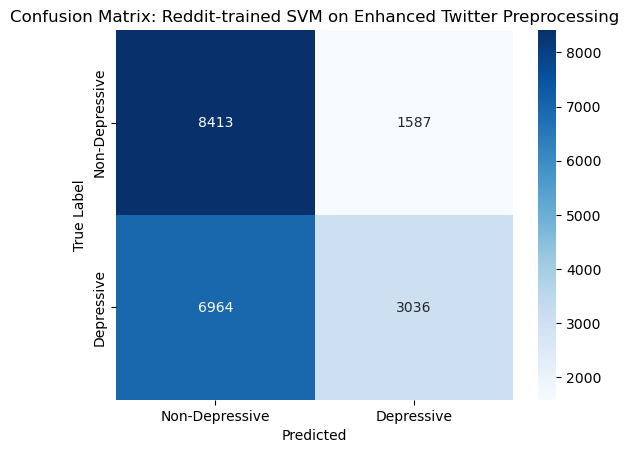

In [6]:
import pandas as pd
import joblib
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


# Setup and load model/vectorizer

nltk.download('stopwords')
nltk.download('wordnet')

svm = joblib.load("svm_reddit_tfidf.pkl")
vectorizer = joblib.load("tfidf_reddit_vectorizer.pkl")


# Load Twitter dataset

twitter_df = pd.read_csv("Mental-Health-Twitter.csv")


# Preprocessing pipeline

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)      # remove URLs
    text = re.sub(r"@\w+", "", text)                # remove mentions
    text = re.sub(r"#(\w+)", r"\1", text)           # remove # but keep word
    text = re.sub(r"[^a-z\s]", "", text)            # remove punctuation, numbers, symbols
    text = re.sub(r'\s+', ' ', text).strip()        # normalize spaces
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_tweet)


# Transform Twitter text using Reddit TF-IDF vectorizer

X_twitter = vectorizer.transform(twitter_df["clean_text"])
y_twitter = twitter_df["label"]


# Predict using Reddit-trained SVM

predicted_depression = svm.predict(X_twitter)


# Evaluate performance

print(" Twitter Accuracy:", accuracy_score(y_twitter, predicted_depression))
print("\nTwitter Classification Report:\n",
      classification_report(y_twitter, predicted_depression, zero_division=0))


# Visualize confusion matrix

cm = confusion_matrix(y_twitter, predicted_depression)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: Reddit-trained SVM on Enhanced Twitter Preprocessing")
plt.show()

# ------------------------------
# Suggested improvements:

#  - Re-train Reddit SVM using bi-grams/trigrams and sublinear_tf=True in TF-IDF:
#    vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,3), sublinear_tf=True)
#  - Apply GridSearchCV to find best ‘C’ for SVM
#  - Try LogisticRegression, SGDClassifier, or fine-tuned BERT baseline for comparison


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Twitter train (20%): 4000
Twitter test (100%): 20000
Combined training dataset: 128444 samples
 Model saved as 'svm_reddit_twitter_mixed.pkl'

===================== Full Twitter Dataset EVALUATION =====================
Accuracy on Full Twitter Dataset: 0.6352

Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.77      0.68     10000
           1       0.68      0.50      0.58     10000

    accuracy                           0.64     20000
   macro avg       0.65      0.64      0.63     20000
weighted avg       0.65      0.64      0.63     20000



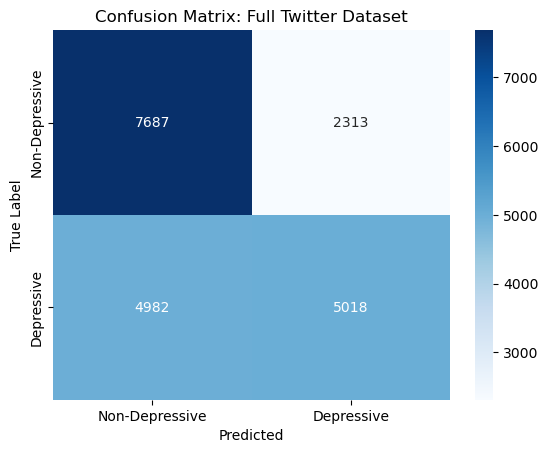

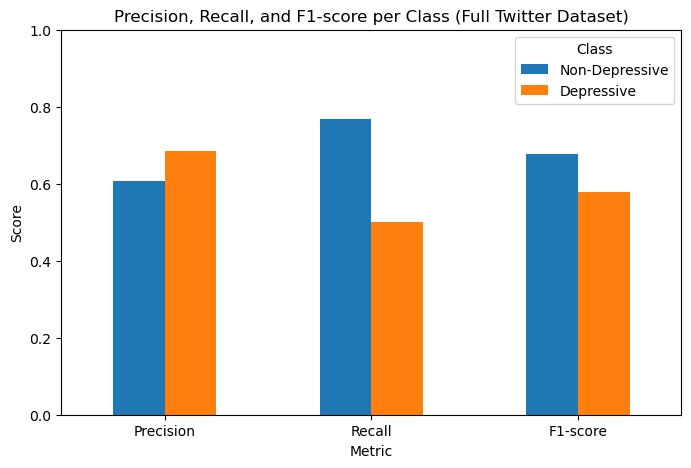

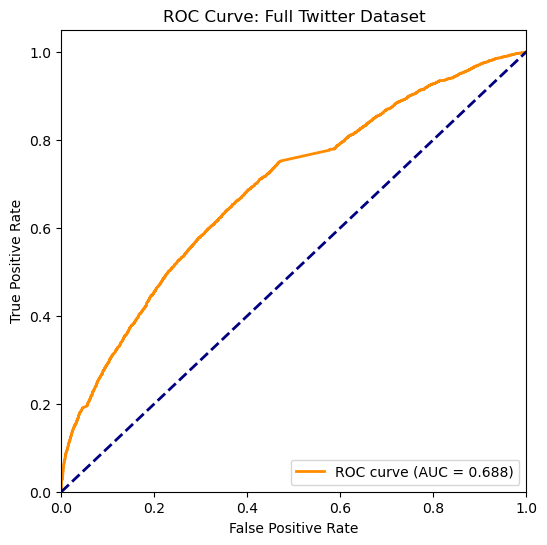


===================== Full Reddit Dataset EVALUATION =====================
Accuracy on Full Reddit Dataset: 0.9561

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.95      0.97     84907
           1       0.90      0.97      0.93     39537

    accuracy                           0.96    124444
   macro avg       0.94      0.96      0.95    124444
weighted avg       0.96      0.96      0.96    124444



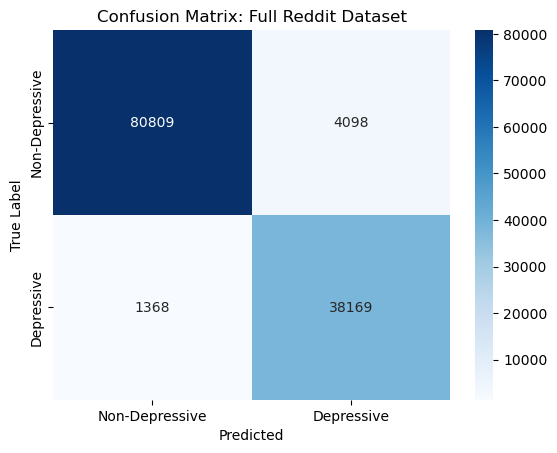

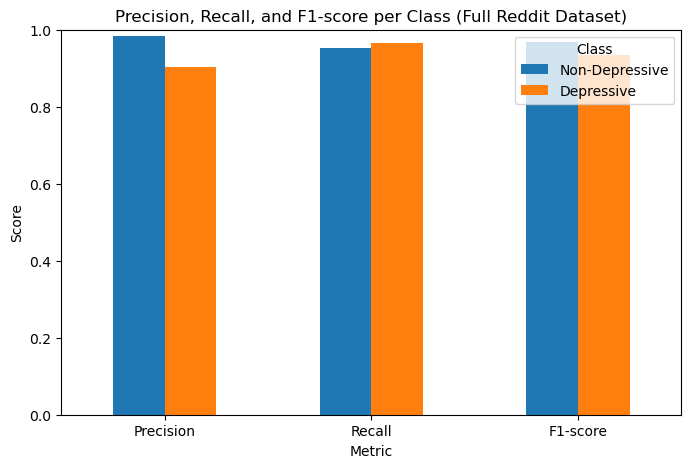

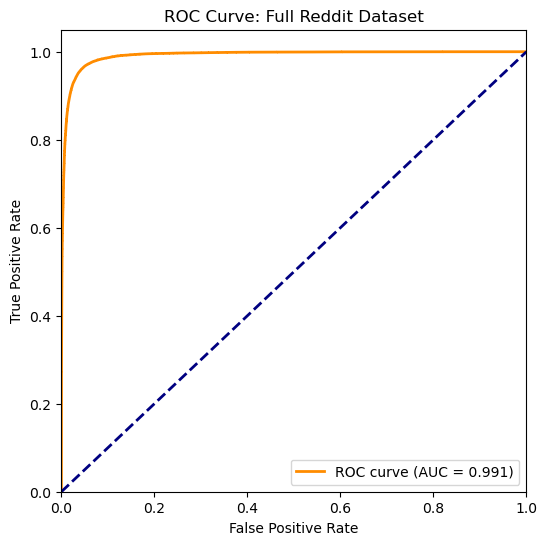

In [14]:
# ============================================================
#  TRAIN: Reddit + 20% Twitter | TEST: Full Twitter + Full Reddit
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, f1_score, precision_score, recall_score
)

# ------------------------------------------------------------
# 1. Load Reddit datasets
# ------------------------------------------------------------
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)

# Label Reddit data
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

# ------------------------------------------------------------
# 2. Text Preprocessing
# ------------------------------------------------------------
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

# ------------------------------------------------------------
# 3. Load and preprocess Twitter dataset
# ------------------------------------------------------------
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_text)
twitter_df["label"] = twitter_df["label"].astype(int)

# ------------------------------------------------------------
# 4. Split Twitter dataset: 20% for training, 100% for testing
# ------------------------------------------------------------
twitter_train, _ = train_test_split(
    twitter_df,
    train_size=0.2,
    random_state=42,
    stratify=twitter_df["label"]
)

twitter_test = twitter_df.copy()

print(f"Twitter train (20%): {len(twitter_train)}")
print(f"Twitter test (100%): {len(twitter_test)}")

# ------------------------------------------------------------
# 5. Combine Reddit + 20% Twitter for training
# ------------------------------------------------------------
reddit_df = combined_df.copy()
reddit_df["clean_text"] = reddit_df["post"].astype(str).apply(preprocess_text)

train_mix = pd.concat([reddit_df, twitter_train], ignore_index=True)
print(f"Combined training dataset: {len(train_mix)} samples")

# ------------------------------------------------------------
# 6. TF-IDF Vectorization
# ------------------------------------------------------------
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vectorizer.fit_transform(train_mix["clean_text"])
y_train = train_mix["label"]

joblib.dump(vectorizer, "tfidf_reddit_twitter_vectorizer.pkl")

# ------------------------------------------------------------
# 7. Train Linear SVM model
# ------------------------------------------------------------
svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X_train, y_train)
joblib.dump(svm, "svm_reddit_twitter_mixed.pkl")
print(" Model saved as 'svm_reddit_twitter_mixed.pkl'")

# ------------------------------------------------------------
# 8. Helper: Evaluation function
# ------------------------------------------------------------
def evaluate_model(name, df, vectorizer, model):
    print(f"\n===================== {name} EVALUATION =====================")
    X = vectorizer.transform(df["clean_text"])
    y_true = df["label"]
    y_pred = model.predict(X)

    acc = accuracy_score(y_true, y_pred)
    print(f"Accuracy on {name}: {acc:.4f}")
    print("\nClassification Report:\n", classification_report(y_true, y_pred, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Non-Depressive", "Depressive"],
                yticklabels=["Non-Depressive", "Depressive"])
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True Label")
    plt.show()

    # F1, Precision, Recall
    f1 = f1_score(y_true, y_pred, average=None)
    precision = precision_score(y_true, y_pred, average=None)
    recall = recall_score(y_true, y_pred, average=None)

    metrics_df = pd.DataFrame({
        "Metric": ["Precision", "Recall", "F1-score"],
        "Non-Depressive": [precision[0], recall[0], f1[0]],
        "Depressive": [precision[1], recall[1], f1[1]]
    })

    metrics_df.set_index("Metric", inplace=True)
    metrics_df.plot(kind='bar', figsize=(8,5))
    plt.title(f"Precision, Recall, and F1-score per Class ({name})")
    plt.ylabel("Score")
    plt.ylim(0,1)
    plt.xticks(rotation=0)
    plt.legend(title="Class")
    plt.show()

    # ROC Curve
    y_score = model.decision_function(X)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, color='darkorange', lw=2,
             label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve: {name}')
    plt.legend(loc="lower right")
    plt.show()

# ------------------------------------------------------------
# 9. Evaluate on BOTH Twitter and Reddit datasets
# ------------------------------------------------------------
vectorizer = joblib.load("tfidf_reddit_twitter_vectorizer.pkl")
svm = joblib.load("svm_reddit_twitter_mixed.pkl")

# Twitter (Full)
evaluate_model("Full Twitter Dataset", twitter_test, vectorizer, svm)

# Reddit (Full)
evaluate_model("Full Reddit Dataset", reddit_df, vectorizer, svm)


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Twitter train (40%): 8000
Combined training dataset: 132444 samples
 Model saved as 'svm_reddit_twitter_mixed.pkl'

===================== Full Twitter Dataset EVALUATION =====================
Accuracy on Full Twitter Dataset: 0.6646

Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.75      0.69     10000
           1       0.70      0.58      0.63     10000

    accuracy                           0.66     20000
   macro avg       0.67      0.66      0.66     20000
weighted avg       0.67      0.66      0.66     20000



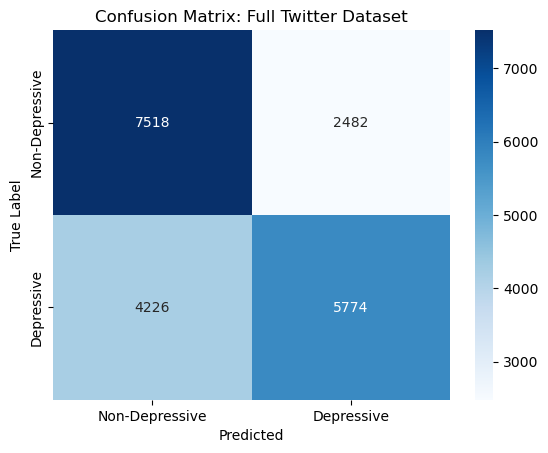

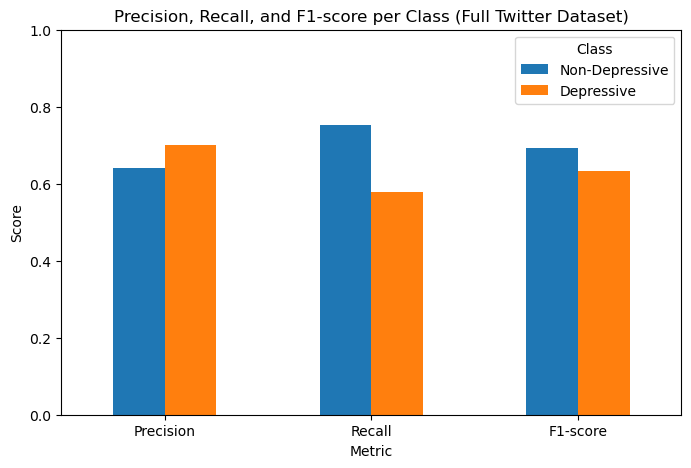

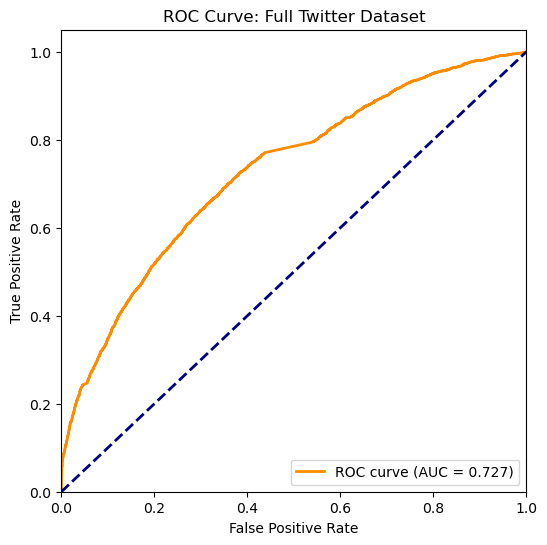


===================== Full Reddit Dataset EVALUATION =====================
Accuracy on Full Reddit Dataset: 0.9524

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.95      0.96     84907
           1       0.89      0.96      0.93     39537

    accuracy                           0.95    124444
   macro avg       0.94      0.96      0.95    124444
weighted avg       0.95      0.95      0.95    124444



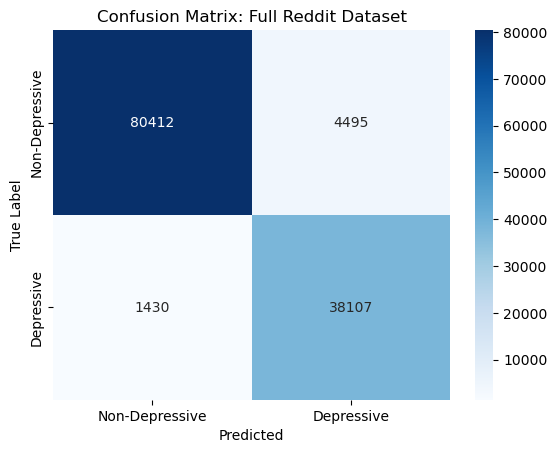

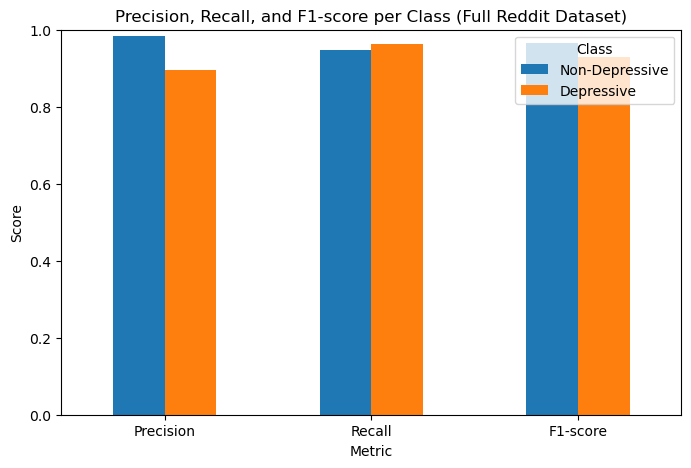

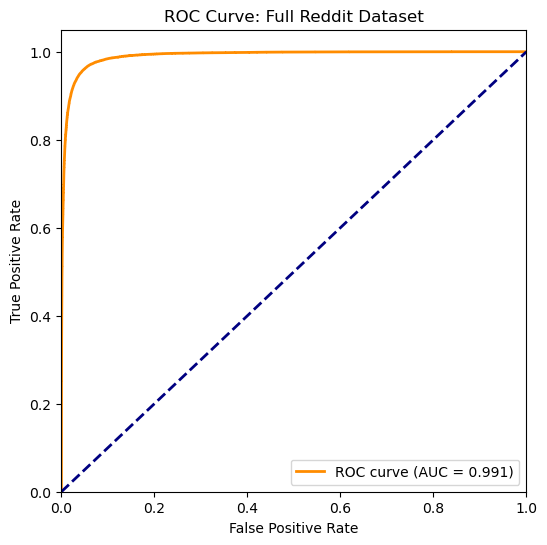

In [16]:
# ============================================================
#  TRAIN: Reddit + 20% Twitter | TEST: Full Twitter + Full Reddit
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, f1_score, precision_score, recall_score
)

# ------------------------------------------------------------
# 1. Load Reddit datasets
# ------------------------------------------------------------
reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)

# Label Reddit data
depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)

# ------------------------------------------------------------
# 2. Text Preprocessing
# ------------------------------------------------------------
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

# ------------------------------------------------------------
# 3. Load and preprocess Twitter dataset
# ------------------------------------------------------------
twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_text)
twitter_df["label"] = twitter_df["label"].astype(int)

# ------------------------------------------------------------
# 4. Split Twitter dataset: 20% for training, 100% for testing
# ------------------------------------------------------------
twitter_train, _ = train_test_split(
    twitter_df,
    train_size=0.4,
    random_state=42,
    stratify=twitter_df["label"]
)

twitter_test = twitter_df.copy()

print(f"Twitter train (40%): {len(twitter_train)}")

# ------------------------------------------------------------
# 5. Combine Reddit + 40% Twitter for training
# ------------------------------------------------------------
reddit_df = combined_df.copy()
reddit_df["clean_text"] = reddit_df["post"].astype(str).apply(preprocess_text)

train_mix = pd.concat([reddit_df, twitter_train], ignore_index=True)
print(f"Combined training dataset: {len(train_mix)} samples")

# ------------------------------------------------------------
# 6. TF-IDF Vectorization
# ------------------------------------------------------------
vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)
X_train = vectorizer.fit_transform(train_mix["clean_text"])
y_train = train_mix["label"]

joblib.dump(vectorizer, "tfidf_reddit_twitter_vectorizer.pkl")

# ------------------------------------------------------------
# 7. Train Linear SVM model
# ------------------------------------------------------------
svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X_train, y_train)
joblib.dump(svm, "svm_reddit_twitter_mixed.pkl")
print(" Model saved as 'svm_reddit_twitter_mixed.pkl'")

# ------------------------------------------------------------
# 8. Helper: Evaluation function
# ------------------------------------------------------------
def evaluate_model(name, df, vectorizer, model):
    print(f"\n===================== {name} EVALUATION =====================")
    X = vectorizer.transform(df["clean_text"])
    y_true = df["label"]
    y_pred = model.predict(X)

    acc = accuracy_score(y_true, y_pred)
    print(f"Accuracy on {name}: {acc:.4f}")
    print("\nClassification Report:\n", classification_report(y_true, y_pred, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=["Non-Depressive", "Depressive"],
                yticklabels=["Non-Depressive", "Depressive"])
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True Label")
    plt.show()

    # F1, Precision, Recall
    f1 = f1_score(y_true, y_pred, average=None)
    precision = precision_score(y_true, y_pred, average=None)
    recall = recall_score(y_true, y_pred, average=None)

    metrics_df = pd.DataFrame({
        "Metric": ["Precision", "Recall", "F1-score"],
        "Non-Depressive": [precision[0], recall[0], f1[0]],
        "Depressive": [precision[1], recall[1], f1[1]]
    })

    metrics_df.set_index("Metric", inplace=True)
    metrics_df.plot(kind='bar', figsize=(8,5))
    plt.title(f"Precision, Recall, and F1-score per Class ({name})")
    plt.ylabel("Score")
    plt.ylim(0,1)
    plt.xticks(rotation=0)
    plt.legend(title="Class")
    plt.show()

    # ROC Curve
    y_score = model.decision_function(X)
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(6,6))
    plt.plot(fpr, tpr, color='darkorange', lw=2,
             label=f'ROC curve (AUC = {roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve: {name}')
    plt.legend(loc="lower right")
    plt.show()

# ------------------------------------------------------------
# 9. Evaluate on BOTH Twitter and Reddit datasets
# ------------------------------------------------------------
vectorizer = joblib.load("tfidf_reddit_twitter_vectorizer.pkl")
svm = joblib.load("svm_reddit_twitter_mixed.pkl")

# Twitter (Full)
evaluate_model("Full Twitter Dataset", twitter_test, vectorizer, svm)

# Reddit (Full)
evaluate_model("Full Reddit Dataset", reddit_df, vectorizer, svm)


<>:77: SyntaxWarning: invalid escape sequence '\ '
<>:77: SyntaxWarning: invalid escape sequence '\ '
C:\Users\Minhtu\AppData\Local\Temp\ipykernel_25392\1489237275.py:77: SyntaxWarning: invalid escape sequence '\ '
  print("\ Model Evaluation on Full Twitter Dataset:")
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


 Loaded Twitter dataset: (20000, 12)
label
1    10000
0    10000
Name: count, dtype: int64
 TF-IDF vectorizer saved as 'tfidf_twitter_full_vectorizer.pkl'
 Model saved as 'svm_twitter_full.pkl'
\ Model Evaluation on Full Twitter Dataset:
Accuracy: 0.9196

 Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.93      0.92     10000
           1       0.92      0.91      0.92     10000

    accuracy                           0.92     20000
   macro avg       0.92      0.92      0.92     20000
weighted avg       0.92      0.92      0.92     20000



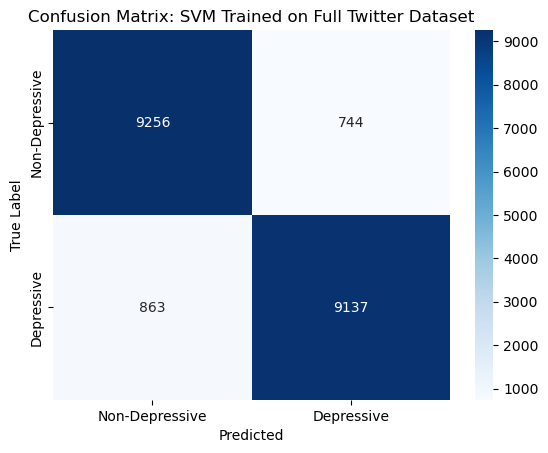

In [3]:
# ============================================================
#  TRAIN + EVALUATE: Full Twitter Dataset 
# ============================================================

import pandas as pd
import joblib
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


#  Setup text preprocessing

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)

#  Load and preprocess Twitter dataset

twitter_df = pd.read_csv("Mental-Health-Twitter.csv")
twitter_df["clean_text"] = twitter_df["post_text"].astype(str).apply(preprocess_text)
twitter_df["label"] = twitter_df["label"].astype(int)

print(" Loaded Twitter dataset:", twitter_df.shape)
print(twitter_df["label"].value_counts())


#  TF-IDF Vectorization on full dataset

vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1,2), sublinear_tf=True)
X = vectorizer.fit_transform(twitter_df["clean_text"])
y = twitter_df["label"]

# Save vectorizer
joblib.dump(vectorizer, "tfidf_twitter_full_vectorizer.pkl")
print(" TF-IDF vectorizer saved as 'tfidf_twitter_full_vectorizer.pkl'")


#  Train SVM on full Twitter data

svm = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000)
svm.fit(X, y)

# Save trained model
joblib.dump(svm, "svm_twitter_full.pkl")
print(" Model saved as 'svm_twitter_full.pkl'")


#  Evaluate on the same dataset (self-evaluation)

y_pred = svm.predict(X)

accuracy = accuracy_score(y, y_pred)
report = classification_report(y, y_pred, zero_division=0)
cm = confusion_matrix(y, y_pred)

print("\ Model Evaluation on Full Twitter Dataset:")
print("Accuracy:", round(accuracy, 4))
print("\n Classification Report:\n", report)


#  Confusion Matrix Visualization

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix: SVM Trained on Full Twitter Dataset")
plt.show()


 Loaded pretrained SVM model and TF-IDF vectorizer.


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Minhtu\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


 Preprocessing Reddit text...

 Accuracy on Reddit dataset: 0.4287

 Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.17      0.29     84907
           1       0.35      0.97      0.52     39537

    accuracy                           0.43    124444
   macro avg       0.65      0.57      0.41    124444
weighted avg       0.75      0.43      0.37    124444



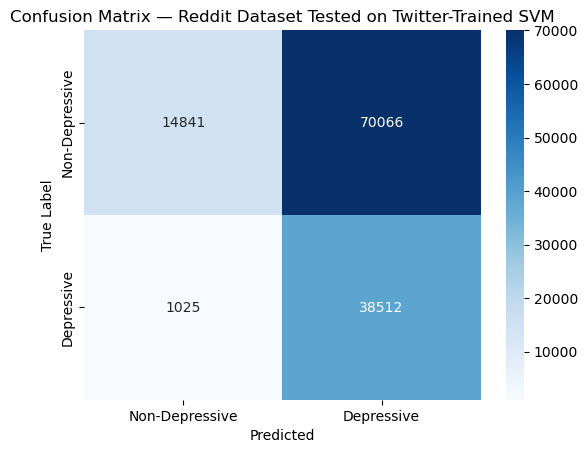


 Accuracy per subreddit:
  addiction       → 0.9769
  adhd            → 0.0295
  alcoholism      → 0.9586
  anxiety         → 0.9854
  conspiracy      → 0.3260
  fitness         → 0.0523
  jokes           → 0.4226
  meditation      → 0.0835
  mentalhealth    → 0.9865
  relationship    → 0.0098
  suicidewatch    → 0.9565
  teaching        → 0.0871


In [2]:
# ============================================================
#  TEST TWITTER-TRAINED MODEL ON REDDIT DATASET 
# ============================================================

import pandas as pd
import joblib
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


#  Load saved model + vectorizer

vectorizer = joblib.load("tfidf_twitter_full_vectorizer.pkl")
svm = joblib.load("svm_twitter_full.pkl")
print(" Loaded pretrained SVM model and TF-IDF vectorizer.")


#  Setup preprocessing 

nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    return " ".join(tokens)


#  Load Reddit datasets

reddit_datasets = {
    'addiction': pd.read_csv('addiction_2019_features_tfidf_256.csv'),
    'adhd': pd.read_csv('adhd_2019_features_tfidf_256.csv'),
    'alcoholism': pd.read_csv('alcoholism_2019_features_tfidf_256.csv'),
    'anxiety': pd.read_csv('anxiety_2019_features_tfidf_256.csv'),
    'jokes': pd.read_csv('jokes_2019_features_tfidf_256.csv'),
    'mentalhealth': pd.read_csv('mentalhealth_2019_features_tfidf_256.csv'),
    'conspiracy': pd.read_csv('conspiracy_2019_features_tfidf_256.csv'),
    'fitness': pd.read_csv('fitness_2019_features_tfidf_256.csv'),
    'meditation': pd.read_csv('meditation_2019_features_tfidf_256.csv'),
    'relationship': pd.read_csv('relationships_2019_features_tfidf_256.csv'),
    'teaching': pd.read_csv('teaching_2019_features_tfidf_256.csv'),
    'suicidewatch': pd.read_csv('suicidewatch_2019_features_tfidf_256.csv'),
}

for name, df in reddit_datasets.items():
    df['subreddit_name'] = name

combined_df = pd.concat(reddit_datasets.values(), ignore_index=True)


#  Preprocess Reddit posts

print(" Preprocessing Reddit text...")
combined_df['clean_post'] = combined_df['post'].astype(str).apply(preprocess_text)


#  Label Reddit data

depressive_subs = ['suicidewatch', 'mentalhealth', 'anxiety', 'addiction', 'alcoholism']
combined_df['label'] = combined_df['subreddit_name'].apply(lambda x: 1 if x in depressive_subs else 0)


# Transform Reddit data using Twitter vectorizer

X_test = vectorizer.transform(combined_df['clean_post'])
y_test = combined_df['label']


#  Predict using the Twitter-trained SVM model

y_pred = svm.predict(X_test)


#  Evaluate results

accuracy = accuracy_score(y_test, y_pred)
print(f"\n Accuracy on Reddit dataset: {accuracy:.4f}")

print("\n Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Non-Depressive", "Depressive"],
            yticklabels=["Non-Depressive", "Depressive"])
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.title("Confusion Matrix — Reddit Dataset Tested on Twitter-Trained SVM")
plt.show()

# Per-subreddit accuracy

print("\n Accuracy per subreddit:")
for name, group in combined_df.groupby('subreddit_name'):
    acc = accuracy_score(group['label'], y_pred[group.index])
    print(f"  {name:<15} → {acc:.4f}")
